# 02 · Analysis — is each vehicle paying for itself, and where is money lost?

Questions from the owner:
1. **Availability.** How many working days did each vehicle actually work, and what did the lost days cost?
2. **Unit economics.** What does a kilometre earn and cost? Which costs matter?
3. **Control.** Do kilometres, fuel and revenue agree with each other?
4. **Operations.** When is the vehicle most profitable, and does the driver's schedule capture it?
5. **Decision.** How long does a vehicle take to pay back, and should a third vehicle be bought now?

Money values are **indexed AOA** (real kwanza × a confidential factor): ratios, percentages, km, trips and payback months are exact. The full analysis uses **V01**, which has 96 days of history (1 Jul – 4 Oct 2026). V02 has only 36 days, split between two drivers and two platforms.

In [1]:
import re
from pathlib import Path

import duckdb
import pandas as pd

DATA = Path("../data/anonymized")
TABLES = ["daily", "trips", "costs", "odometer", "vehicles", "drivers"]

con = duckdb.connect()
for t in TABLES:
    con.execute(f"CREATE VIEW {t} AS SELECT * FROM read_csv_auto('{(DATA / (t + '.csv')).as_posix()}')")

sql_text = Path("../sql/kpis.sql").read_text(encoding="utf-8")
QUERIES = dict(re.findall(r"-- name: (\w+)\n(.*?)(?=\n-- name:|\Z)", sql_text, re.S))

def run(name: str) -> pd.DataFrame:
    return con.execute(QUERIES[name]).df()

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from matplotlib.patches import Patch

IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)
SURFACE, INK, INK_2, GRID, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#c9c8c2"
STATUS_COLORS = {"operated": "#2a78d6", "driver_absence": "#eb6834", "no_driver": "#1baf7a",
                 "network_outage": "#eda100", "rest_day": NEUTRAL}
STATUS_LABELS = {"operated": "Operated", "driver_absence": "Driver absent", "no_driver": "No driver",
                 "network_outage": "Phone network down", "rest_day": "Rest day"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})
kaoa = mtick.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}k")
daily = con.execute("SELECT * FROM daily").df()
daily["date"] = pd.to_datetime(daily["date"])

## 1 · Availability — how many working days were actually worked?

In [2]:
avail = run("availability")
avail

,vehicle_id,calendar_days,working_days,operated_days,availability
0,V01,96,85,65,0.765
1,V02,36,33,17,0.515


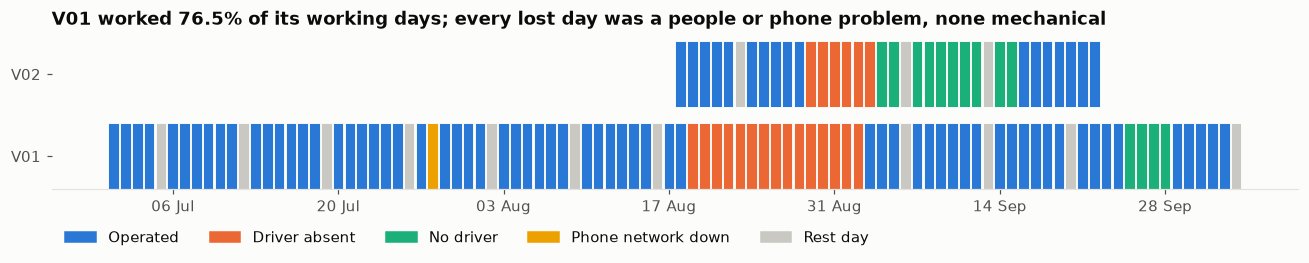

In [3]:
fig, ax = plt.subplots(figsize=(12, 2.6))
for row, vehicle in enumerate(["V01", "V02"]):
    g = daily[daily["vehicle_id"] == vehicle]
    ax.bar(g["date"], 0.8, bottom=row - 0.4, width=0.9,
           color=g["status"].map(STATUS_COLORS), edgecolor=SURFACE, linewidth=0.6)
ax.set_yticks([0, 1], ["V01", "V02"])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(handles=[Patch(color=c, label=STATUS_LABELS[s]) for s, c in STATUS_COLORS.items()],
          ncol=5, loc="upper left", bbox_to_anchor=(0, -0.18), frameon=False)
ax.set_title(f"V01 worked {avail.loc[0, 'availability']:.1%} of its working days; "
             f"every lost day was a people or phone problem, none mechanical")
fig.tight_layout()
fig.savefig(IMAGES / "01_fleet_calendar.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
cost = run("downtime_cost")
cost["cause"] = cost["cause"].map(STATUS_LABELS)
display(cost)
v01_lost = cost.loc[cost["vehicle_id"] == "V01", "lost_revenue_aoa"].sum()
v01_rev = daily.loc[daily["vehicle_id"] == "V01", "net_revenue_aoa"].sum()
print(f"V01: {v01_lost:,.0f} AOA of revenue lost on 20 working days = {v01_lost / v01_rev:.0%} of what it actually earned")

,vehicle_id,cause,lost_days,lost_revenue_aoa
0,V01,Driver absent,15,564686.0
1,V02,No driver,10,204735.0
2,V01,No driver,4,150583.0
3,V02,Driver absent,6,122841.0
4,V01,Phone network down,1,37646.0


V01: 752,915 AOA of revenue lost on 20 working days = 31% of what it actually earned


**Reading:** V01 lost **20 working days in 96**, 15 of them in one continuous driver absence. Valued at its average day, that revenue equals **about 31% of what the vehicle actually earned**. V02 spent most of its first five weeks without a driver.

**Every lost day was a people or phone problem; none was mechanical.** That points to two cheap fixes:
- a **standby driver** shared by the fleet;
- a **second SIM** from another network in each service phone.

## 2 · Unit economics — what does a kilometre earn and cost?

In [5]:
econ = run("unit_economics")
econ

,vehicle_id,calendar_days,net_revenue,fuel,maintenance,driver_salary,wash_and_parking,equipment,margin,margin_rate
0,V01,96,2446972.0,263182.0,242701.0,348852.0,153958.0,0.0,1438279.0,0.588
1,V02,36,348049.0,32358.0,81316.0,79013.0,10383.0,3322.0,141657.0,0.407


In [6]:
odo = run("odometer_intervals")
v01_odo = odo[odo["vehicle_id"] == "V01"]
km = v01_odo["km"].sum()
window = daily[(daily["vehicle_id"] == "V01") & (daily["date"] >= v01_odo["from_date"].min())
               & (daily["date"] < v01_odo["to_date"].max())]
costs = con.execute("SELECT * FROM costs WHERE vehicle_id = 'V01'").df()
v01_days = (daily["vehicle_id"] == "V01").sum()
per_day = lambda cats: costs.loc[costs["category"].isin(cats), "amount_aoa"].sum() / v01_days
per_km = pd.Series({
    "Fuel": window["fuel_aoa"].sum() / km,
    "Maintenance": costs.loc[costs["category"] == "maintenance", "amount_aoa"].sum() / 21_000,  # 3 services, 7,000 km each
    "Driver salary": per_day(["driver_salary"]) * len(window) / km,
    "Wash & parking": per_day(["wash", "parking"]) * len(window) / km,
})
revenue_per_km = window["net_revenue_aoa"].sum() / km
per_km["Margin"] = revenue_per_km - per_km.sum()
print(f"V01, {km:,} km between odometer readings · maintenance per km = {per_km['Maintenance'] / per_km['Fuel']:.0%} of fuel per km")
per_km.round(1).to_frame("indexed AOA per km")

V01, 17,730 km between odometer readings · maintenance per km = 78% of fuel per km


,indexed AOA per km
Fuel,14.8
Maintenance,11.6
Driver salary,17.2
Wash & parking,7.6
Margin,61.8


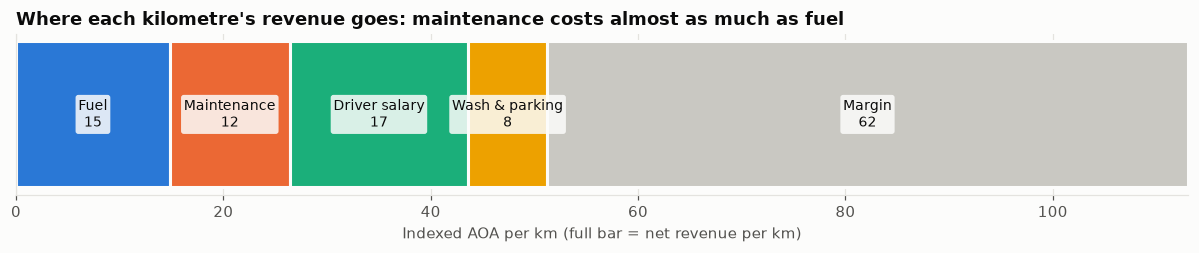

In [7]:
fig, ax = plt.subplots(figsize=(11, 2.4))
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#c9c8c2"]
left = 0
for (name, value), color in zip(per_km.items(), colors):
    ax.barh(0, value, left=left, color=color, edgecolor=SURFACE, linewidth=2, height=0.55)
    ax.text(left + value / 2, 0, f"{name}\n{value:,.0f}", ha="center", va="center", fontsize=9,
            color=INK, bbox=dict(boxstyle="round,pad=0.2", fc=SURFACE, ec="none", alpha=0.85))
    left += value
ax.set_xlim(0, revenue_per_km)
ax.set_yticks([])
ax.grid(axis="x")
ax.set_xlabel("Indexed AOA per km (full bar = net revenue per km)")
ax.set_title("Where each kilometre's revenue goes: maintenance costs almost as much as fuel")
fig.tight_layout()
fig.savefig(IMAGES / "02_cost_per_km.png", dpi=150)
plt.show()

**Reading:** V01 keeps about **59%** of its net revenue as margin, before insurance and taxes. **Maintenance costs ~78% as much as fuel per km.**
- At ~1,700 km a week, a 7,000 km service comes **every 4 weeks**.
- Engine oil is about 75% of each service bill.
- A cheaper oil supplier is the single largest saving available in the cost structure.

## 3 · Control — do kilometres, fuel and revenue agree?

In [8]:
odo

,vehicle_id,from_date,to_date,km,operated_days,net_revenue,fuel_aoa,fuel_per_km,revenue_per_km
0,V01,2026-07-12,2026-07-19,1835,6,206080.0,21912.0,11.9,112.3
1,V01,2026-07-19,2026-08-09,5347,17,614639.0,85621.0,16.0,115.0
2,V01,2026-08-09,2026-08-16,1783,6,208323.0,28444.0,16.0,116.8
3,V01,2026-08-16,2026-08-31,1219,2,56188.0,8980.0,7.4,46.1
4,V01,2026-08-31,2026-09-15,3035,10,360965.0,46728.0,15.4,118.9
5,V01,2026-09-15,2026-09-20,1696,5,195922.0,24981.0,14.7,115.5
6,V01,2026-09-20,2026-09-25,1162,4,149937.0,14951.0,12.9,129.0
7,V01,2026-09-25,2026-10-04,1653,5,212247.0,31565.0,19.1,128.4
8,V02,2026-08-17,2026-08-31,1996,10,170420.0,29866.0,15.0,85.4
9,V02,2026-08-31,2026-09-16,1076,0,0.0,0.0,0.0,0.0


In [9]:
v01_typical = v01_odo.loc[v01_odo["operated_days"] >= 4, "km"].sum() / v01_odo.loc[v01_odo["operated_days"] >= 4, "operated_days"].sum()
check = odo.copy()
check["expected_km"] = (check["operated_days"] * v01_typical).round()
check["km_without_revenue"] = check["km"] - check["expected_km"]
suspect = check[check["km_without_revenue"] > 500]  # more than ~1.5 working days of driving unexplained
print(f"Typical V01 working day: {v01_typical:,.0f} km · unexplained km in flagged intervals: {suspect['km_without_revenue'].sum():,.0f}")
suspect[["vehicle_id", "from_date", "to_date", "km", "operated_days", "expected_km", "km_without_revenue"]]

Typical V01 working day: 312 km · unexplained km in flagged intervals: 1,672


,vehicle_id,from_date,to_date,km,operated_days,expected_km,km_without_revenue
3,V01,2026-08-16,2026-08-31,1219,2,623.0,596.0
9,V02,2026-08-31,2026-09-16,1076,0,0.0,1076.0


**Reading:** in two intervals the odometer advanced far more than the trips explain:
- **V01, 16–31 Aug:** 1,219 km with only 2 days worked. A typical day is ~300 km, so about 600 km are unexplained.
- **V02, 31 Aug – 16 Sep:** 1,076 km while the vehicle had no driver and earned nothing.

That is **~1,700 km with no revenue**, about one week of normal driving in fuel and wear. This is a control gap, not a conclusion about anyone: the trips app only sees paid rides. The fix is the GPS telematics already installed. Reconciling GPS km with app trips every week is the next step, and it is the purpose of the owner's separate fleet-tracking project.

Fuel cost per km also drifted upwards after the first week (table below). Part of it may be fuel bought without a receipt; it is worth tracking per tank.

In [10]:
fuel = v01_odo[v01_odo["operated_days"] >= 4][["from_date", "to_date", "km", "fuel_per_km"]].copy()
fuel["vs_first_week"] = (fuel["fuel_per_km"] / fuel["fuel_per_km"].iloc[0] - 1).map("{:+.0%}".format)
fuel

,from_date,to_date,km,fuel_per_km,vs_first_week
0,2026-07-12,2026-07-19,1835,11.9,+0%
1,2026-07-19,2026-08-09,5347,16.0,+34%
2,2026-08-09,2026-08-16,1783,16.0,+34%
4,2026-08-31,2026-09-15,3035,15.4,+29%
5,2026-09-15,2026-09-20,1696,14.7,+24%
6,2026-09-20,2026-09-25,1162,12.9,+8%
7,2026-09-25,2026-10-04,1653,19.1,+61%


## 4 · Operations — when is the vehicle most profitable?

Contract start 05:30 · average first trip 06:25


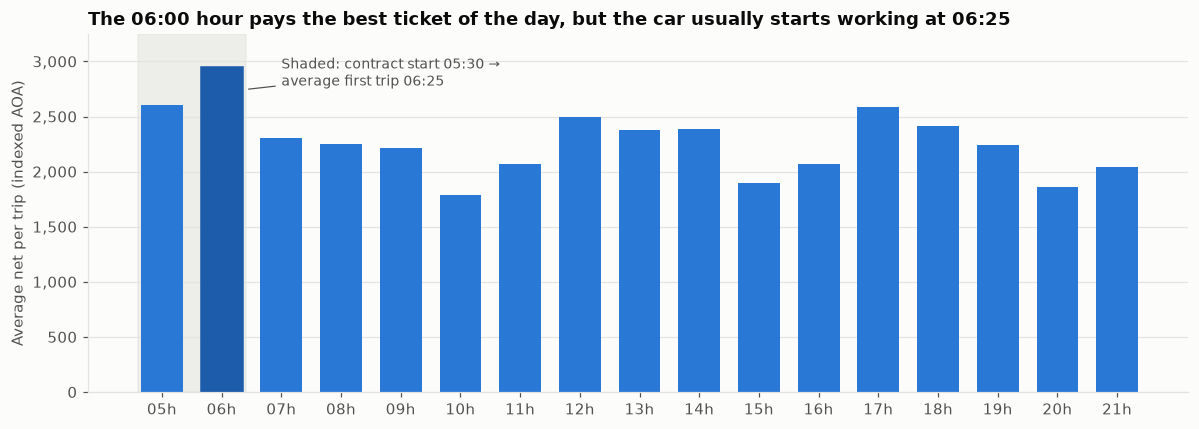

In [11]:
hours = run("revenue_by_hour")
v01_hours = hours[hours["vehicle_id"] == "V01"]
first = pd.to_datetime(daily.loc[(daily["vehicle_id"] == "V01") & (daily["status"] == "operated"), "first_trip"].astype(str).str[:5], format="%H:%M")
avg_first = (first.dt.hour * 60 + first.dt.minute).mean()
print(f"Contract start 05:30 · average first trip {int(avg_first // 60):02d}:{int(avg_first % 60):02d}")

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(v01_hours["hour"], v01_hours["avg_ticket"], color="#2a78d6", width=0.7)
bars[list(v01_hours["hour"]).index(6)].set_color("#1c5cab")
top = v01_hours["avg_ticket"].max()
ax.axvspan(4.6, 6.4, color=GRID, alpha=0.6, zorder=0)
ax.annotate("Shaded: contract start 05:30 →\naverage first trip 06:25", xy=(6.4, top * 0.93), xytext=(7.0, top * 0.98),
            color=INK_2, fontsize=9, va="center", arrowprops=dict(arrowstyle="-", color=INK_2, lw=0.8))
ax.set_ylim(0, top * 1.1)
ax.set_xticks(v01_hours["hour"], [f"{h:02d}h" for h in v01_hours["hour"]])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylabel("Average net per trip (indexed AOA)")
ax.set_title("The 06:00 hour pays the best ticket of the day, but the car usually starts working at 06:25")
fig.tight_layout()
fig.savefig(IMAGES / "03_ticket_by_hour.png", dpi=150)
plt.show()

**Reading:** trips starting between 06:00 and 06:59 pay the **highest average ticket (+28% on the day's average)**, with early commuters going to work. The contract says work starts at 05:30, but the first trip comes at **06:25 on average**. Enforcing the start time is worth roughly one extra early trip a day, **~8% more revenue per day** per vehicle, with no extra cost.

**Platform comparison (V02, small sample):**

In [12]:
run("driver_productivity")

,driver_id,vehicle_id,platform,operated_days,trips_per_day,net_per_day_aoa,net_per_trip_aoa,platform_fee_rate,avg_span_first_to_last_trip_h
0,D01,V01,Yango,59,16.1,36980.0,2301.0,0.162,13.0
1,D02,V02,Heetch,10,8.4,17042.0,2029.0,0.171,7.8
2,D03,V02,Yango,7,14.6,25375.0,1741.0,0.162,11.8


Both platforms charge a similar fee (~16–17% of fares). The gap is **demand**, not commission: on Yango, V02 did **14.6 trips/day** against **8.4 on Heetch**. That is the main reason V02 moved to Yango. With only 7–10 days per platform, this is an indication, not a proof.

## 5 · Decision — payback and the third vehicle

In [13]:
v01 = econ[econ["vehicle_id"] == "V01"].iloc[0]
monthly_margin = v01["margin"] / v01["calendar_days"] * 30
fuel_rate = v01["fuel"] / v01["net_revenue"]
recovered = v01_lost * (1 - fuel_rate) / v01["calendar_days"] * 30  # lost revenue net of the fuel it would have used
early_start = v01_hours.loc[v01_hours["hour"] == 6, "avg_ticket"].iloc[0] * (1 - fuel_rate) * 26  # +1 early trip per working day
new_vehicle = con.execute("SELECT acquisition_aoa FROM vehicles WHERE vehicle_id = 'V02'").fetchone()[0]
scenarios = pd.DataFrame({
    "monthly_margin_aoa": [monthly_margin, monthly_margin + recovered, monthly_margin + recovered + early_start],
}, index=["As observed (76.5% availability)", "No lost working days", "No lost days + 05:30 start"])
scenarios["payback_months_new_vehicle"] = new_vehicle / scenarios["monthly_margin_aoa"]
scenarios.round(1)

,monthly_margin_aoa,payback_months_new_vehicle
As observed (76.5% availability),449462.2,19.0
No lost working days,659442.1,13.0
No lost days + 05:30 start,727939.1,11.8


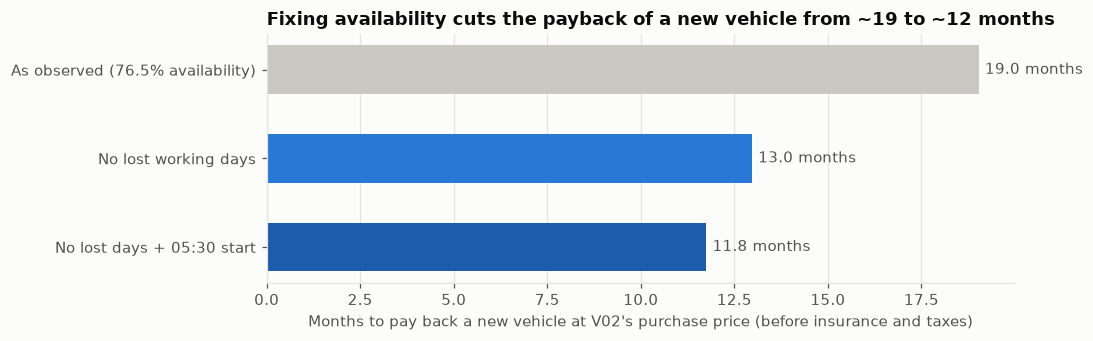

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.2))
y = range(len(scenarios))[::-1]
bars = ax.barh(list(y), scenarios["payback_months_new_vehicle"], color=["#c9c8c2", "#2a78d6", "#1c5cab"], height=0.55)
ax.bar_label(bars, labels=[f"{m:.1f} months" for m in scenarios["payback_months_new_vehicle"]], padding=4, color=INK_2)
ax.set_yticks(list(y), scenarios.index)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Months to pay back a new vehicle at V02's purchase price (before insurance and taxes)")
ax.set_title("Fixing availability cuts the payback of a new vehicle from ~19 to ~12 months")
fig.tight_layout()
fig.savefig(IMAGES / "04_payback_scenarios.png", dpi=150)
plt.show()

**Reading:** at the observed margin, a new vehicle at V02's purchase price pays back in **~19 months**. With no lost working days it would take **~13 months**, and with the 05:30 start enforced **~12 months**.

The first problem is not fleet size; it is that the existing cars stand still on working days. **Recommendation** (see [`docs/decision_memo.md`](../docs/decision_memo.md)):
1. Hire a **standby driver**, shared by the fleet, before buying a third vehicle.
2. Put a **second SIM** in each service phone.
3. **Reconcile GPS km with app trips** every week.
4. **Renegotiate engine oil** for the 7,000 km services.
5. **Buy the third vehicle** once availability holds above 90% for two months.

## Key findings

| # | Finding | Number |
|---|---|---|
| 1 | Lost working days were the biggest leak | V01 **76.5%** availability · lost revenue ≈ **31%** of actual revenue |
| 2 | Maintenance costs almost as much as fuel | maintenance ≈ **78%** of fuel per km · margin **59%** before insurance |
| 3 | Kilometres without revenue | ~**1,700 km** in two intervals: a control gap for GPS reconciliation |
| 4 | The best hour is missed | 06:00 trips pay **+28%**; the average first trip is at 06:25 |
| 5 | Payback depends on availability | ~**19 → 12 months** for a new vehicle |